In [17]:
#!pip install torchvision


In [18]:
import sklearn as sk
import os
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

In [19]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths for all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [20]:
root_dir_path = "./img_align_celeba\\img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [21]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202599 images


In [22]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

## Generator Network

In [23]:
import numpy as np
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [24]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512), 
            nn.ReLU(),

            nn.Linear(512, 1024), 
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels), 
            nn.Tanh() # [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64) 
        return img

        # fake img => 64 x 64 x 3 x batch_size

## Discriminator Network

In [25]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3): # 3 is for RGB
        super(Discriminator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor => 1D
            
            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), 
            nn.Sigmoid() # probability of being real/fake 
        )

    def forward(self, img):
        return self.model(img)

In [26]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [27]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is cpu


In [28]:
generator = generator.to(device)
discriminator = discriminator.to(device)

## Training the GAN

In [29]:
def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device) 

In [30]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/5... batch: 1... G-loss:0.6968065500259399.... D-loss: 0.6936615705490112
for epoch: 1/5... batch: 51... G-loss:0.9643577933311462.... D-loss: 0.2698867619037628
for epoch: 1/5... batch: 101... G-loss:1.85159170627594.... D-loss: 0.13506393134593964
for epoch: 1/5... batch: 151... G-loss:2.659148693084717.... D-loss: 0.21962608397006989
for epoch: 1/5... batch: 201... G-loss:0.5118998289108276.... D-loss: 0.4906531274318695
for epoch: 1/5... batch: 251... G-loss:2.9121346473693848.... D-loss: 0.04431872069835663
for epoch: 1/5... batch: 301... G-loss:2.4097299575805664.... D-loss: 0.09540946036577225
for epoch: 1/5... batch: 351... G-loss:2.6082186698913574.... D-loss: 0.09410150349140167
for epoch: 1/5... batch: 401... G-loss:3.180525779724121.... D-loss: 0.07541732490062714
for epoch: 1/5... batch: 451... G-loss:3.3650448322296143.... D-loss: 0.11230675131082535
for epoch: 1/5... batch: 501... G-loss:3.1122350692749023.... D-loss: 0.1306992769241333
for epoch: 1/5... bat

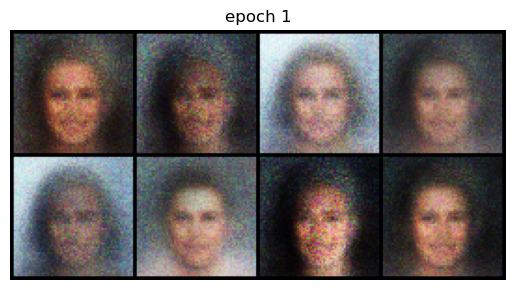

for epoch: 2/5... batch: 1... G-loss:3.6910529136657715.... D-loss: 0.5122289657592773
for epoch: 2/5... batch: 51... G-loss:2.1731839179992676.... D-loss: 0.39461803436279297
for epoch: 2/5... batch: 101... G-loss:2.777503490447998.... D-loss: 0.3553035259246826
for epoch: 2/5... batch: 151... G-loss:2.380518674850464.... D-loss: 0.28521811962127686
for epoch: 2/5... batch: 201... G-loss:2.6130566596984863.... D-loss: 0.2836245894432068
for epoch: 2/5... batch: 251... G-loss:3.293487071990967.... D-loss: 0.4153955280780792
for epoch: 2/5... batch: 301... G-loss:2.855905771255493.... D-loss: 0.41709309816360474
for epoch: 2/5... batch: 351... G-loss:2.669193983078003.... D-loss: 0.4017277956008911
for epoch: 2/5... batch: 401... G-loss:2.317387342453003.... D-loss: 0.38627398014068604
for epoch: 2/5... batch: 451... G-loss:2.2314581871032715.... D-loss: 0.3225271999835968
for epoch: 2/5... batch: 501... G-loss:2.7318835258483887.... D-loss: 0.3005375862121582
for epoch: 2/5... batch: 5

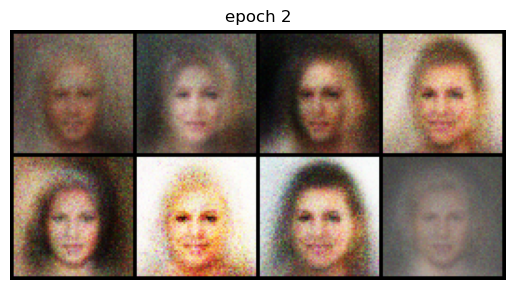

for epoch: 3/5... batch: 1... G-loss:2.1600990295410156.... D-loss: 0.341013640165329
for epoch: 3/5... batch: 51... G-loss:2.3276424407958984.... D-loss: 0.39912497997283936
for epoch: 3/5... batch: 101... G-loss:2.186612367630005.... D-loss: 0.4389391541481018
for epoch: 3/5... batch: 151... G-loss:2.3474273681640625.... D-loss: 0.3925457298755646
for epoch: 3/5... batch: 201... G-loss:2.2103376388549805.... D-loss: 0.43959856033325195
for epoch: 3/5... batch: 251... G-loss:1.9923101663589478.... D-loss: 0.37828928232192993
for epoch: 3/5... batch: 301... G-loss:2.528181314468384.... D-loss: 0.29889336228370667
for epoch: 3/5... batch: 351... G-loss:1.5582939386367798.... D-loss: 0.5745001435279846
for epoch: 3/5... batch: 401... G-loss:1.9395781755447388.... D-loss: 0.32813429832458496
for epoch: 3/5... batch: 451... G-loss:1.8108549118041992.... D-loss: 0.4892789423465729
for epoch: 3/5... batch: 501... G-loss:2.0699639320373535.... D-loss: 0.32242345809936523
for epoch: 3/5... bat

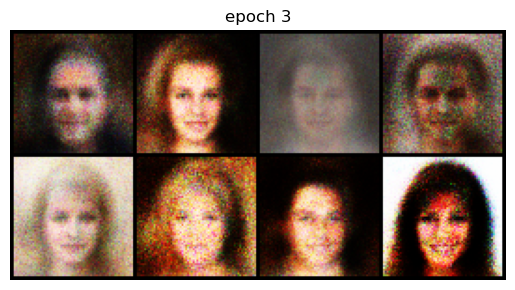

for epoch: 4/5... batch: 1... G-loss:2.023664951324463.... D-loss: 0.47656625509262085
for epoch: 4/5... batch: 51... G-loss:1.676714539527893.... D-loss: 0.48076045513153076
for epoch: 4/5... batch: 101... G-loss:2.4873313903808594.... D-loss: 0.36230725049972534
for epoch: 4/5... batch: 151... G-loss:1.7768858671188354.... D-loss: 0.5470595359802246
for epoch: 4/5... batch: 201... G-loss:1.660355806350708.... D-loss: 0.5592214465141296
for epoch: 4/5... batch: 251... G-loss:2.0162229537963867.... D-loss: 0.4855697453022003
for epoch: 4/5... batch: 301... G-loss:1.3014028072357178.... D-loss: 0.5509107112884521
for epoch: 4/5... batch: 351... G-loss:1.926628828048706.... D-loss: 0.4973528981208801
for epoch: 4/5... batch: 401... G-loss:1.8581706285476685.... D-loss: 0.42920851707458496
for epoch: 4/5... batch: 451... G-loss:1.5274155139923096.... D-loss: 0.46812549233436584
for epoch: 4/5... batch: 501... G-loss:2.1968491077423096.... D-loss: 0.5325808525085449
for epoch: 4/5... batch

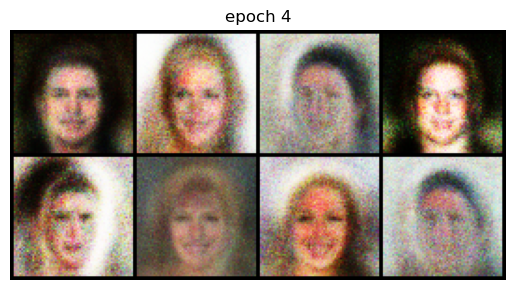

for epoch: 5/5... batch: 1... G-loss:1.5662851333618164.... D-loss: 0.45957595109939575
for epoch: 5/5... batch: 51... G-loss:1.7200613021850586.... D-loss: 0.5209188461303711
for epoch: 5/5... batch: 101... G-loss:1.7972509860992432.... D-loss: 0.4489520192146301
for epoch: 5/5... batch: 151... G-loss:1.5998995304107666.... D-loss: 0.4960613548755646
for epoch: 5/5... batch: 201... G-loss:1.85025954246521.... D-loss: 0.591668963432312
for epoch: 5/5... batch: 251... G-loss:1.871250867843628.... D-loss: 0.4755101501941681
for epoch: 5/5... batch: 301... G-loss:2.0103707313537598.... D-loss: 0.4742647707462311
for epoch: 5/5... batch: 351... G-loss:1.8536332845687866.... D-loss: 0.5545661449432373
for epoch: 5/5... batch: 401... G-loss:2.166718006134033.... D-loss: 0.4629843831062317
for epoch: 5/5... batch: 451... G-loss:1.8115164041519165.... D-loss: 0.5273947715759277
for epoch: 5/5... batch: 501... G-loss:1.27435302734375.... D-loss: 0.5349401235580444
for epoch: 5/5... batch: 551..

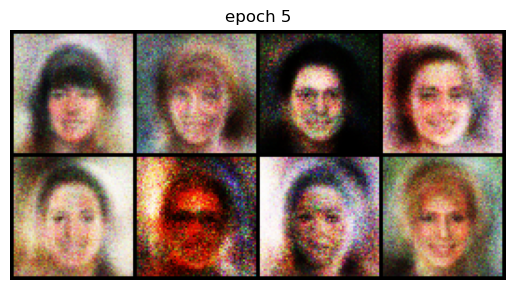

In [31]:
train(generator, discriminator, dataloader, epochs=5)